# Exp5 Approach B — raw signal / Fourier features / theme–slot Gaussian HMM

Same notebook contract as Approach A. Marks are **provisional** until hand-labelled.

Kernel: **panmp**.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from analysis.song_hmm.exp4.spectrogram import plot_eval_slices
from analysis.song_hmm.exp5.paths import GPL_193500, TRAIN_N_WINDOWS, TEST_N_WINDOWS, WORK

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

eval_path = WORK / "results" / "B" / "eval.json"
assert eval_path.is_file(), f"missing {eval_path}; run: python -m analysis.song_hmm.exp5.run_pipeline 3"
data = json.loads(eval_path.read_text())
themes, boundaries = data["themes"], data["boundaries"]
print("n_boundaries", len(boundaries), "n_theme_segments", len(themes))
print("JS", data.get("js_summary"))
print("scores (provisional)", data.get("scores_vs_provisional_marks"))
print("model", data.get("model_meta"))

n_boundaries 5 n_theme_segments 6
JS {'n_pred': 5, 'mean_js_pred': 0.10347435034968695, 'mean_js_random': 0.0415013960637043, 'median_js_pred': 0.07130189935913735, 'median_js_random': 0.0309689234194268}
scores (provisional) {'recall@5s': 0.0, 'precision@5s': 0.0, 'recall@10s': 0.0, 'precision@10s': 0.0, 'f1@10s': 0.0, 'recall@30s': 0.022727272727272728, 'precision@30s': 0.2, 'median_err_s': 12.912000000000262, 'p90_err_s': 12.912000000000262, 'false_alarms_per_h': 1.3333333333333333, 'n_pred': 5.0, 'n_marks': 44.0}
model {'n_themes': 6, 'slot_counts': [3, 3, 6, 3, 5, 8], 'train_score': -624330.7282161926, 'selection': [{'T': 3, 'slot_counts': [3, 3, 6], 'avg_ll': -638973.175377976, 'bic': 33063032650.618702}, {'T': 4, 'slot_counts': [3, 3, 6, 3], 'avg_ll': -632127.2039762409, 'bic': 32708795874.91273}, {'T': 5, 'slot_counts': [3, 3, 6, 3, 5], 'avg_ll': -627740.9083644918, 'bic': 32481833335.513447}, {'T': 6, 'slot_counts': [3, 3, 6, 3, 5, 8], 'avg_ll': -624330.7282161926, 'bic': 3230

In [2]:
print("Every boundary (s / min / h):")
for b in boundaries:
    print(f"  {b:.1f} s | {b/60:.2f} min | {b/3600:.3f} h")

print("\nBoth themes at each boundary:")
for b in boundaries:
    before = [t for t in themes if t["t1"] <= b + 1e-6]
    after = [t for t in themes if t["t0"] >= b - 1e-6]
    left = before[-1] if before else None
    right = after[0] if after else None
    print(
        f"t={b:.1f}: before={left['theme'] if left else None} "
        f"[{left['t0'] if left else None:.1f},{left['t1'] if left else None:.1f}) "
        f"after={right['theme'] if right else None} "
        f"[{right['t0'] if right else None:.1f},{right['t1'] if right else None:.1f})"
    )

Every boundary (s / min / h):
  25203.4 s | 420.06 min | 7.001 h
  25352.4 s | 422.54 min | 7.042 h
  25369.7 s | 422.83 min | 7.047 h
  27122.5 s | 452.04 min | 7.534 h
  27127.3 s | 452.12 min | 7.535 h

Both themes at each boundary:
t=25203.4: before=T1 [25200.5,25203.4) after=T2 [25203.4,25352.4)
t=25352.4: before=T2 [25203.4,25352.4) after=T3 [25352.4,25369.7)
t=25369.7: before=T3 [25352.4,25369.7) after=T4 [25369.7,27122.5)
t=27122.5: before=T4 [25369.7,27122.5) after=T5 [27122.5,27127.3)
t=27127.3: before=T5 [27122.5,27127.3) after=T6 [27127.3,35998.4)


18 slices in /home/hdn008/projects/panMP_whales/analysis/song_hmm/exp5/work/figures/B
slice_00.png


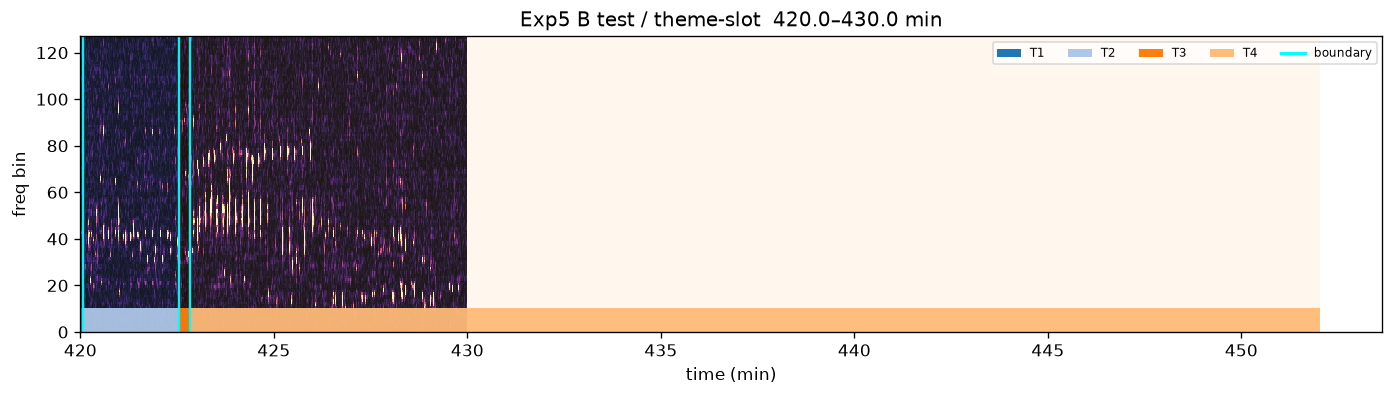

slice_01.png


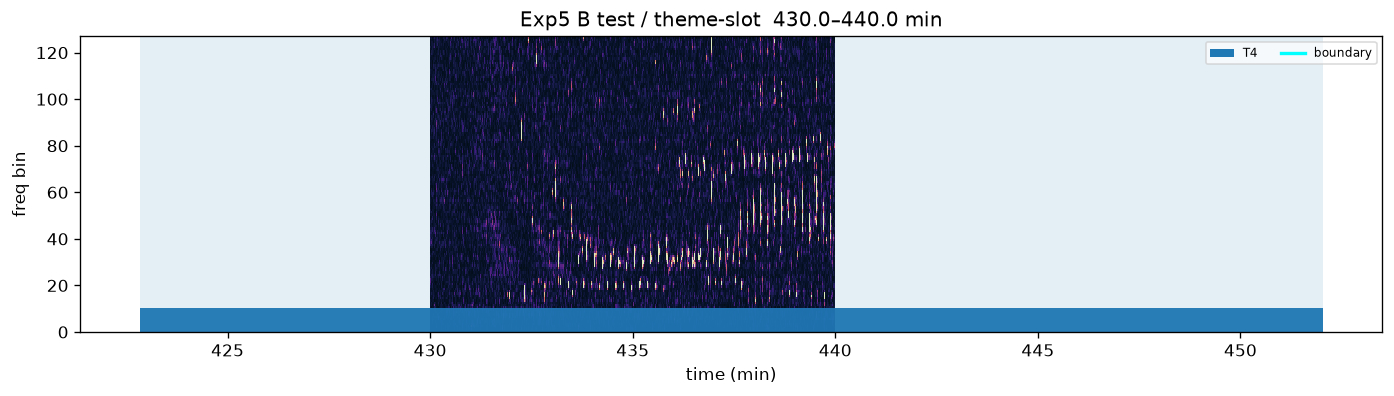

slice_02.png


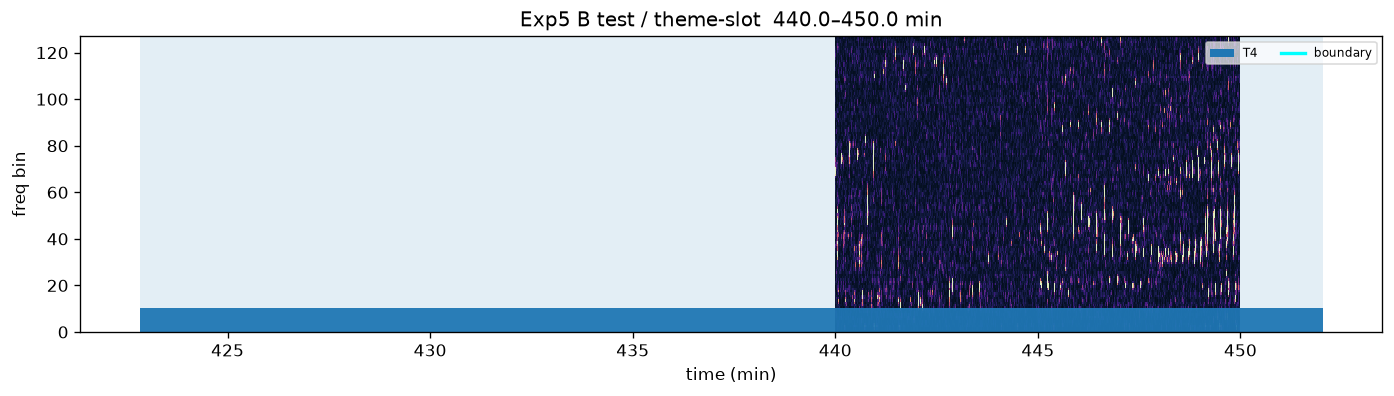

slice_03.png


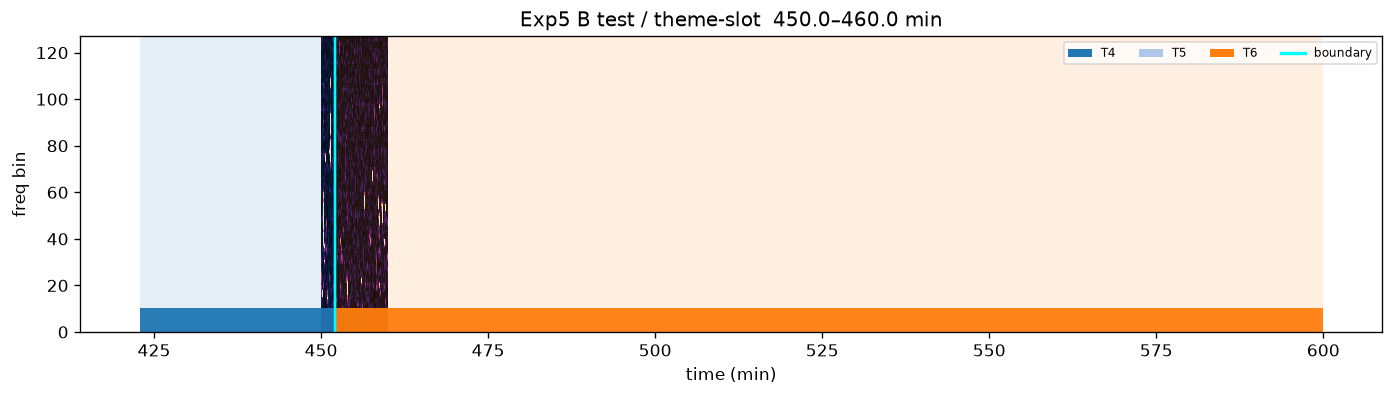

slice_04.png


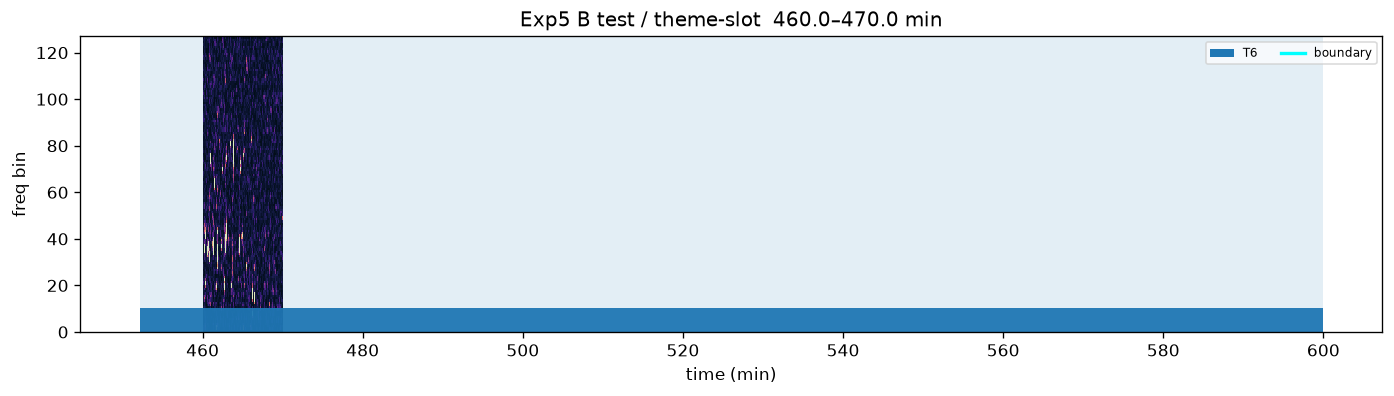

slice_05.png


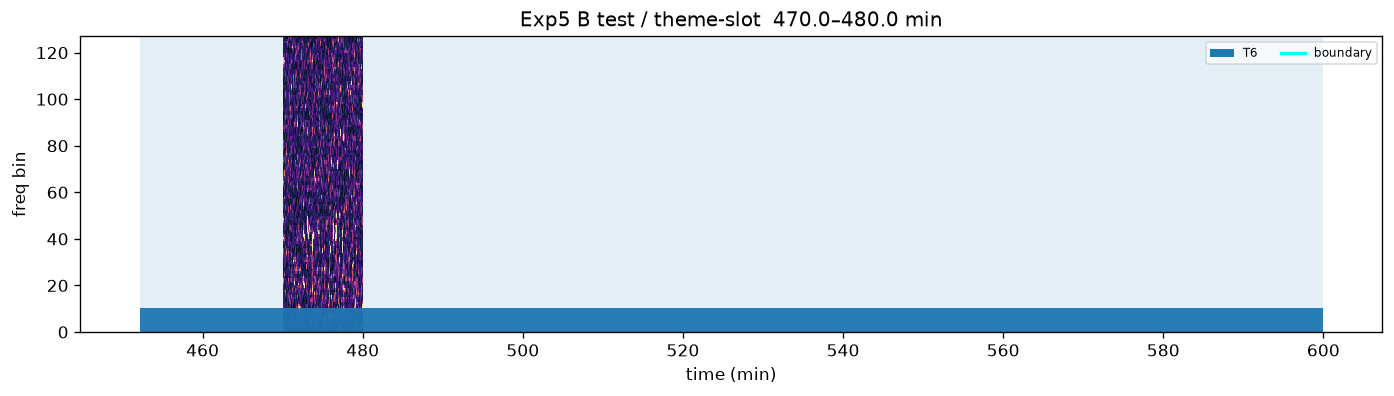

In [3]:
fig_dir = WORK / "figures" / "B"
pngs = sorted(fig_dir.glob("slice_*.png"))
print(f"{len(pngs)} slices in {fig_dir}")
for p in pngs[:6]:
    print(p.name)
    display(Image(filename=str(p)))

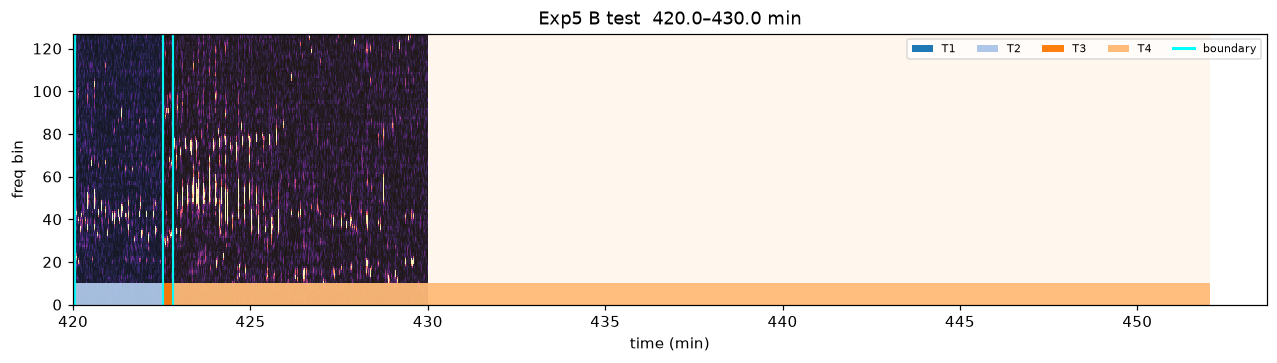

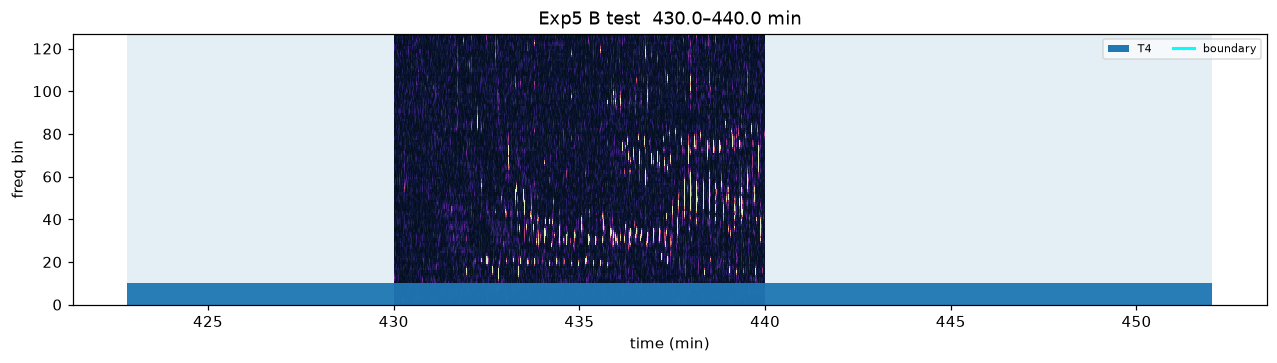

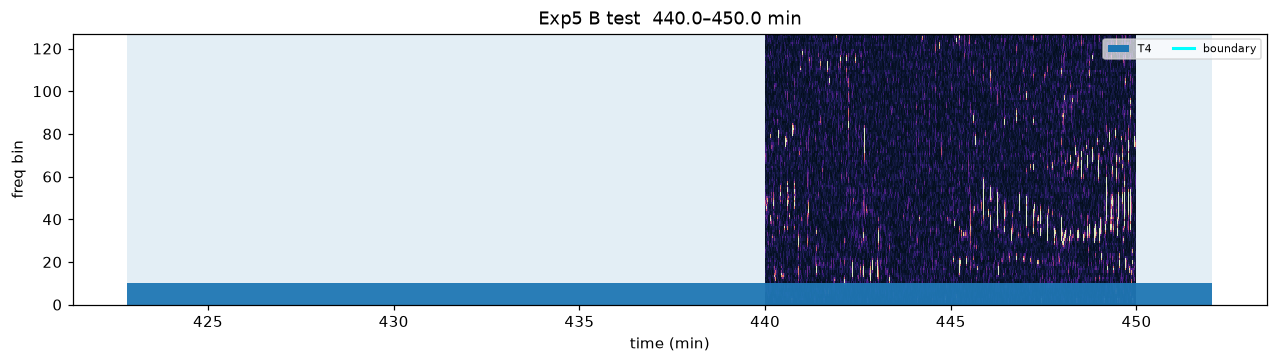

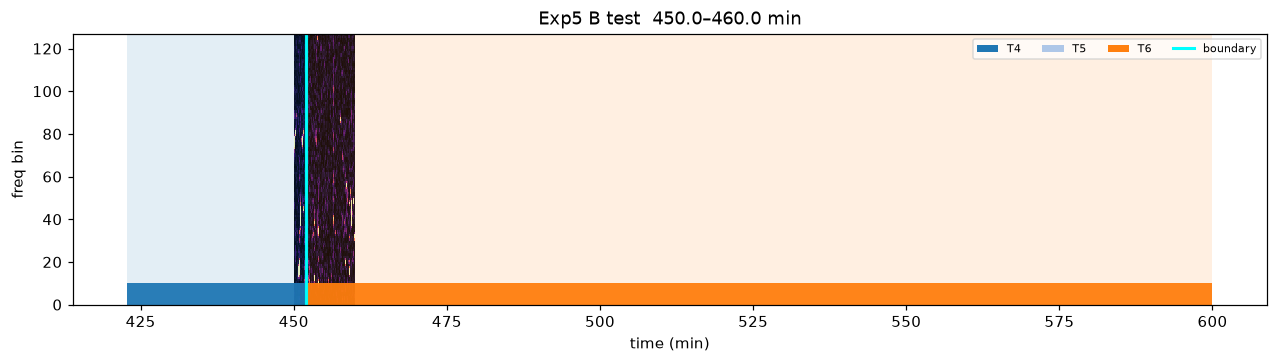

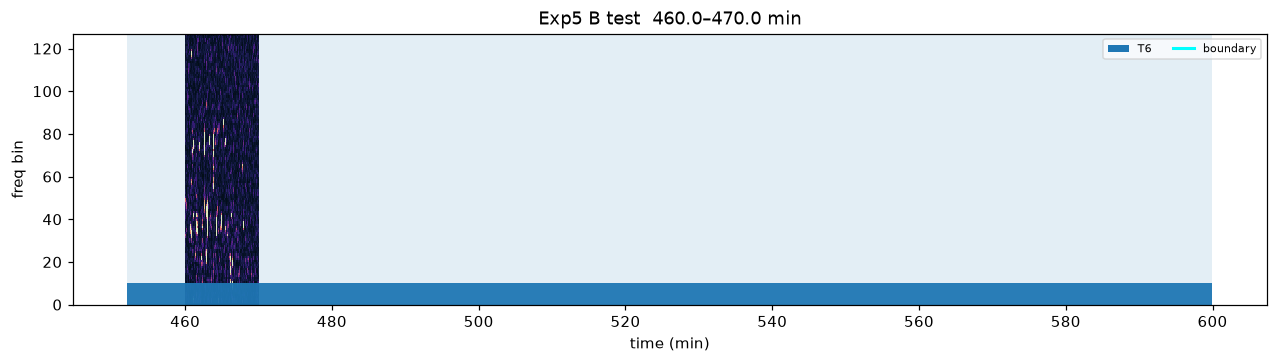

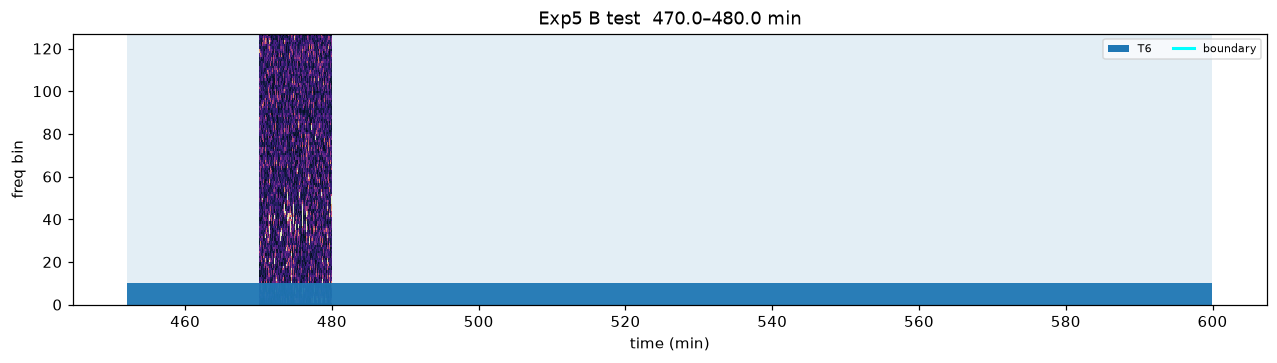

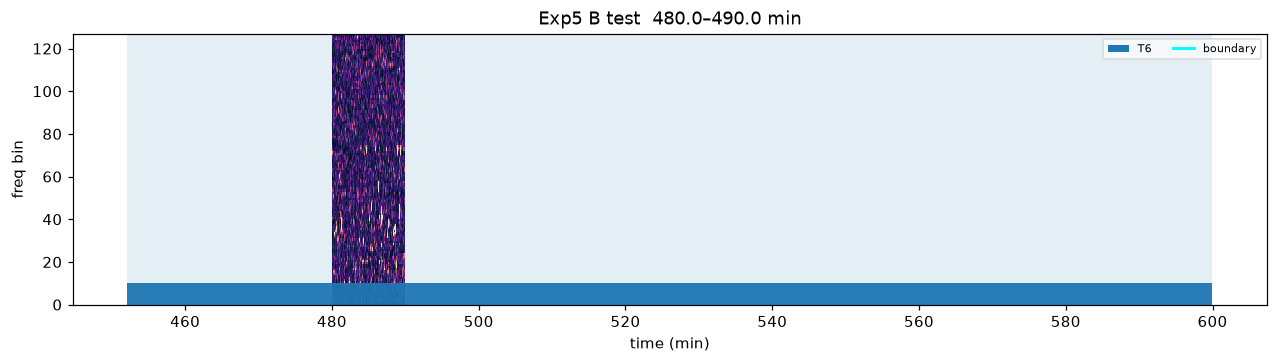

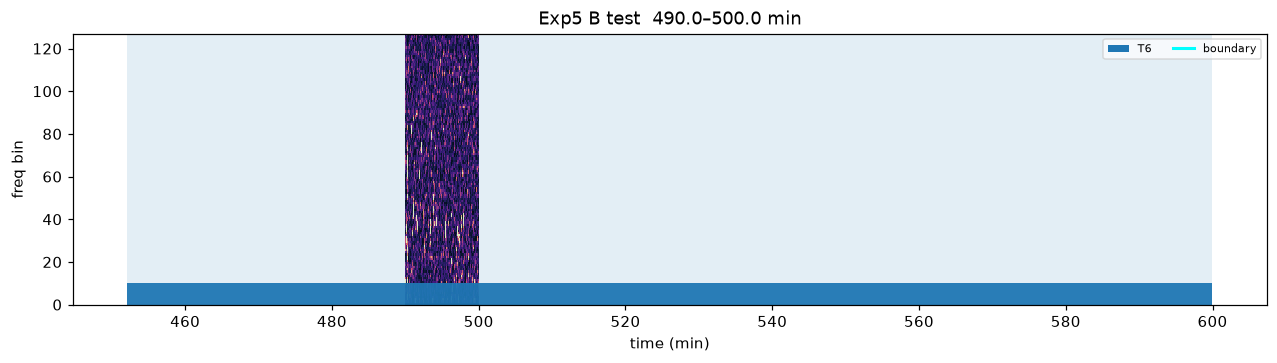

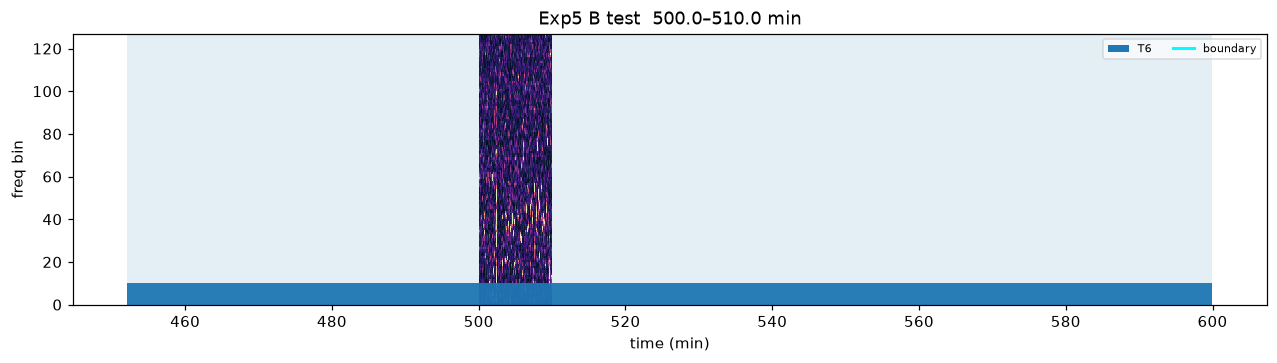

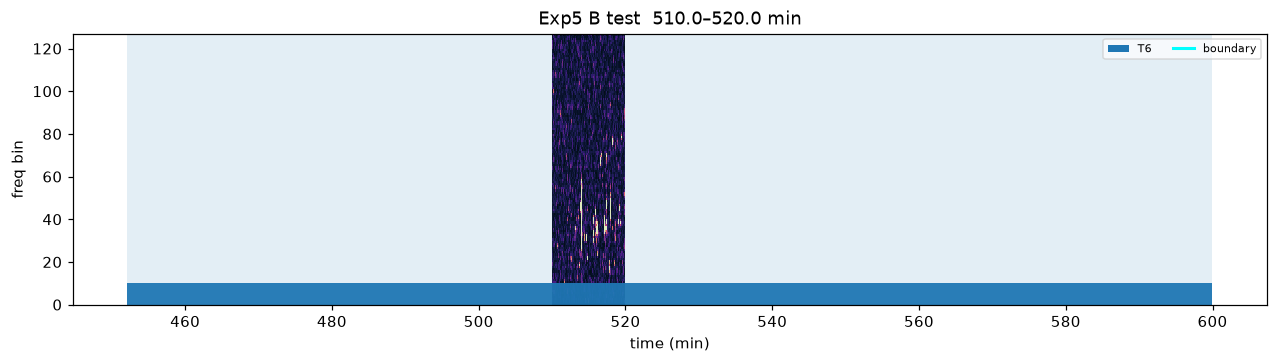

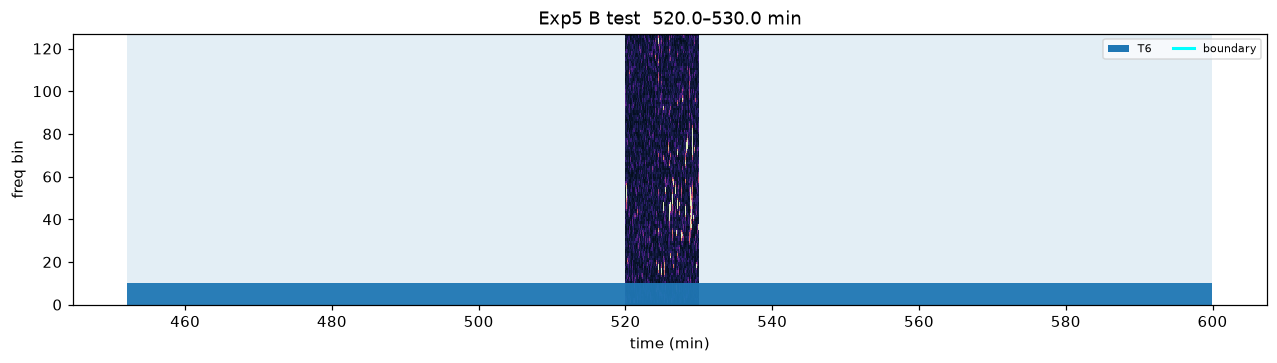

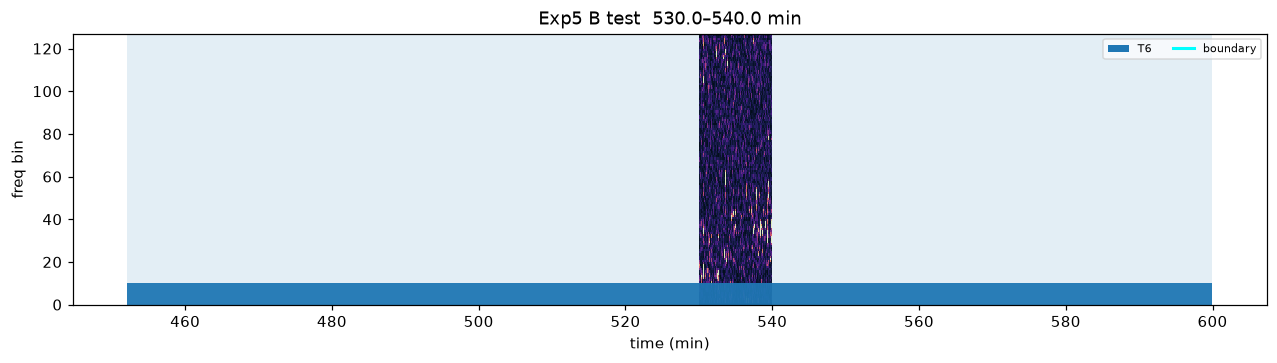

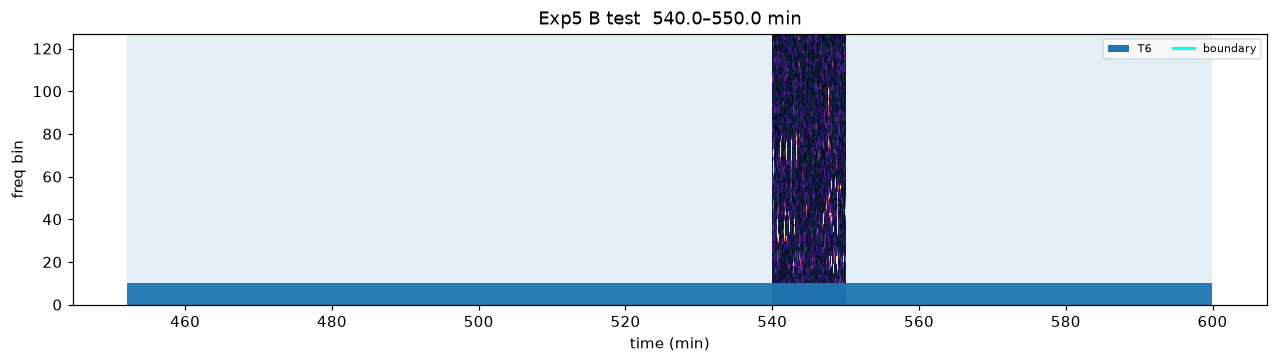

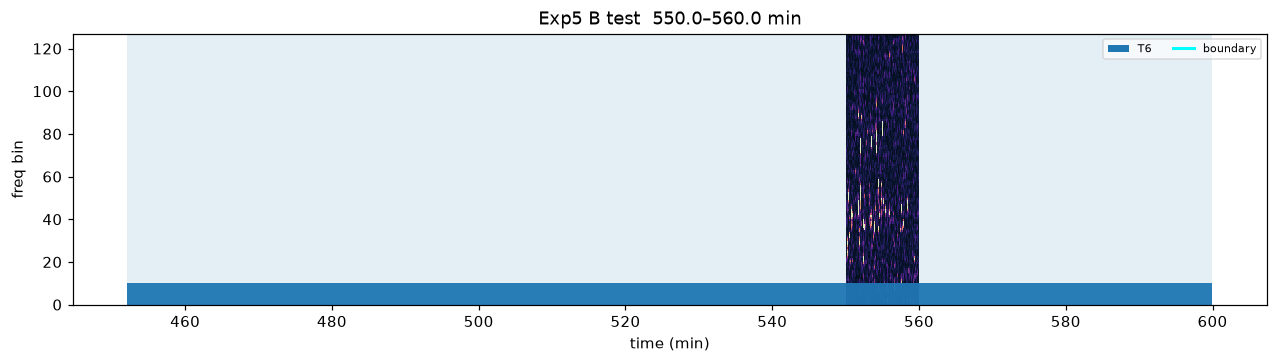

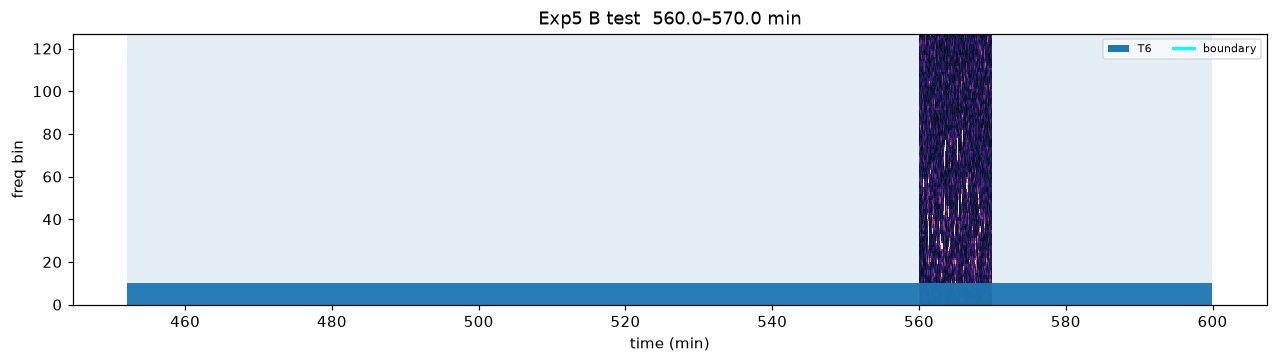

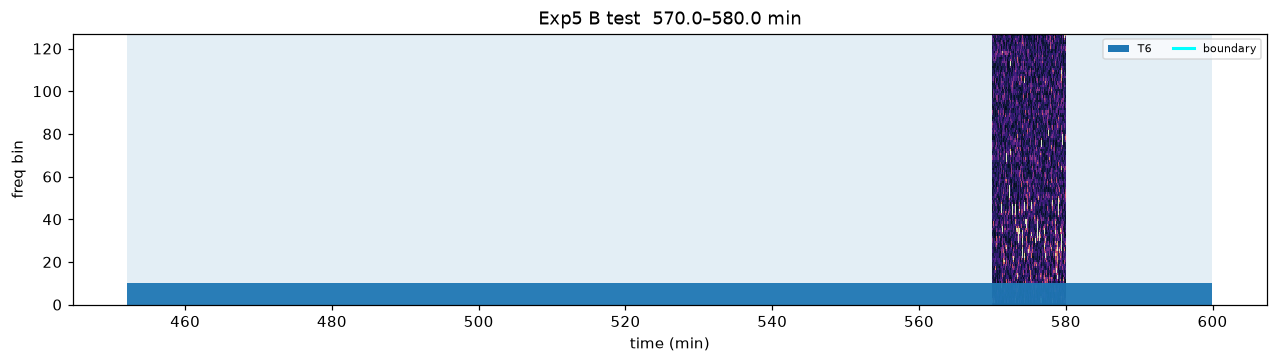

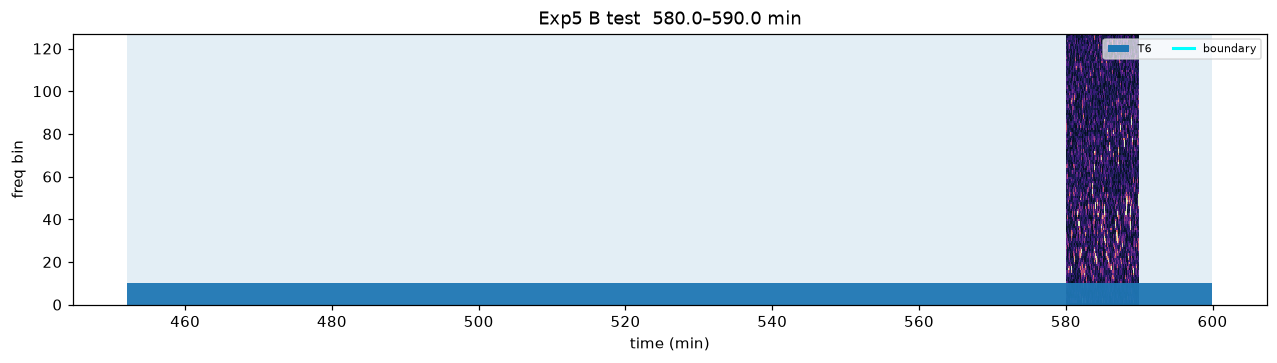

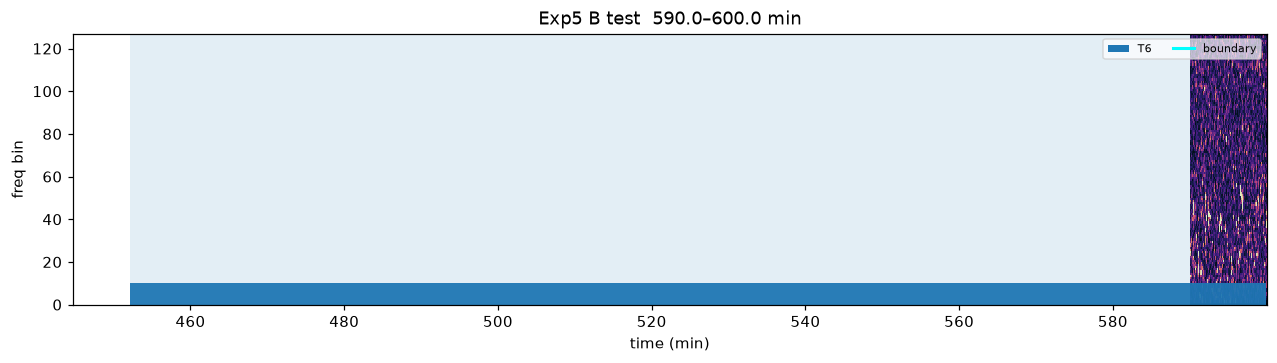

In [4]:
figs = plot_eval_slices(
    GPL_193500, themes, boundaries,
    window_offset=TRAIN_N_WINDOWS, n_windows=TEST_N_WINDOWS,
    slice_s=600.0, title_prefix="Exp5 B test",
)
for fig in figs[:3]:
    display(fig)
    plt.close(fig)